# 04 PROPAGAÇÃO FORMAL DE INCERTEZA, CALIBRAÇÃO DE APONTAMENTO, CORRELAÇÃO RESIDUAL ($L$), FIRN, GIA E BALANÇO DE MASSA

Este caderno documenta a física e a geoestatística da conversão da grade de mudança de elevação ($\text{dh/dt}$) em perda de massa continental ($\text{dM/dt}$ em $\text{Gt/ano}$) e equivalente eustático de nível do mar ($\text{SLE}$ em $\text{mm/ano}$):

$$\frac{dV}{dt} = \sum_{i=1}^{N_{\text{cél}}} \left(\frac{dh_i}{dt} - \frac{d\text{FAC}_i}{dt} - \frac{dB_i}{dt}\right) A_{\text{cél}}, \qquad \frac{dM}{dt} = \rho_{\text{gelo}} \frac{dV}{dt}, \qquad \text{SLE} = -\frac{dM/dt}{361{,}8\text{ Gt/mm}}$$

onde $\rho_{\text{gelo}} = 917\text{ kg m}^{-3}$ (densidade do gelo glacial para perda dinâmica), $\text{FAC}$ é o conteúdo de ar na coluna de firn e $dB/dt$ é a taxa de movimento vertical do embasamento rochoso por Ajuste Isostático Glacial (GIA).

---

## 1. Calibração Empírica do Erro de Geolocalização Horizontal Projetado na Declividade (`thwaites.uncertainty.geolocation`)

O ATBD do produto oficial ATL14/ATL15 r005 (§3.4.4, Smith et al., 2024) aponta o erro de apontamento/geolocalização horizontal $\sigma_{\text{horiz}}$ projetado sobre a declividade superficial $s = |\nabla h|$ como a fonte dominante de erro vertical correlacionado em escalas de dezenas de quilômetros:

$$\sigma_{\text{geo}}^2(s) = \sigma_{v0}^2 + (\sigma_{\text{horiz}}\,s)^2$$

Em vez de assumir valores tabulados, calibramos essa relação diretamente contra $4.347.847$ segmentos ($40$ grânulos representativos) usando as variáveis `sigma_geo_h` e `dh_fit_dx` do próprio ATL06 r007 na nossa área de estudo, por regressão sobre medianas em $24$ quantis de declividade (evitando a cauda de outliers de `sigma_geo_h` que distorce a regressão OLS global):
- **Piso vertical puro calibrado:** $\sigma_{v0} = 0{,}1326\text{ m}$ ($4\times$ maior que o ruído de fóton `h_li_sigma` mediano de $0{,}034\text{ m}$);
- **Incerteza horizontal calibrada:** $\sigma_{\text{horiz}} = 6{,}19\text{ m}$ ($R^2 = 0{,}9978$), em concordância notável com o requisito de projeto da missão ICESat-2 de $6{,}5\text{ m}$ (Luthcke et al., 2021);
- **Propagação por alavancagem orbital (`overpass_leverage`):** Como o erro de apontamento é constante ao longo dos poucos segundos em que uma passagem $k$ cruza o nó, mas independente entre passagens distintas, sua contribuição para a incerteza da tendência é:
  $$\sigma_{\text{dh/dt, geo}} = \frac{\sigma_{\text{geo}}(s)}{\sqrt{\sum_{k=1}^{K_{\text{pass}}} (t_k - \bar{t})^2}}$$
  Com uma mediana de $93{,}5$ passagens por tile e alavancagem temporal $\sum(t_k - \bar{t})^2 = 355{,}1\text{ ano}^2$, obtém-se $\sigma_{\text{dh/dt, geo}} = 0{,}0075\text{ m/ano}$ contra $\sigma_{\text{dh/dt, jackknife}} = 0{,}0572\text{ m/ano}$ (**razão $= 13{,}5\%$**).
- **Conclusão científica:** Na nossa geometria nodal de $15\text{ km}$, o erro de apontamento é fortemente promediado pelas $\sim 94$ passagens. Portanto, a correlação espacial residual de $20\text{--}154\text{ km}$ **não é instrumental**, mas sim **geofísica** (variabilidade interanual espacialmente coerente de precipitação/firn e dinâmica).

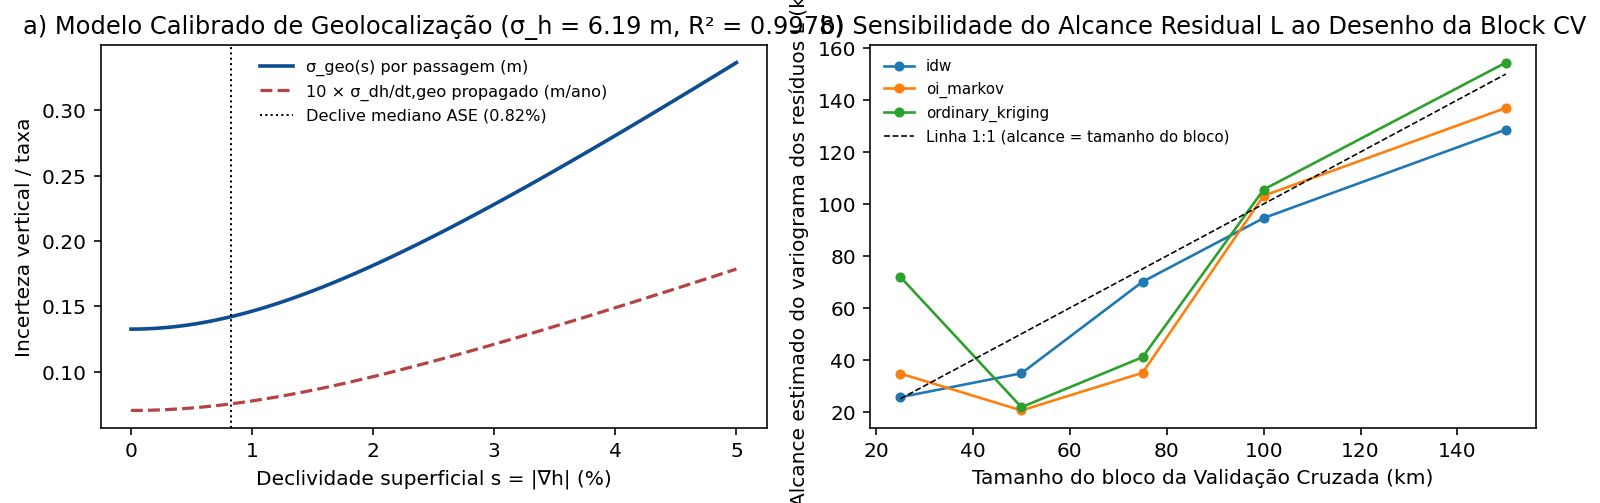

block_km,25.0,50.0,75.0,100.0,150.0
method,,,,,
idw,25.6,34.8,70.0,94.6,128.6
oi_markov,34.7,20.5,35.0,103.1,137.0
ordinary_kriging,71.9,21.8,41.0,105.5,154.4


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sig_rep = json.loads((DATA_DIR / "jja_sigma_corr_report.json").read_text(encoding="utf-8"))
err_sens = json.loads((DATA_DIR / "jja_error_correlation_sensitivity.json").read_text(encoding="utf-8"))
firn_sens = pd.read_csv(DATA_DIR / "jja_firn_sensitivity.csv")

# Curva teórica calibrada sigma_geo(s) vs declividade s
s_vals = np.linspace(0, 0.05, 100)
s_v0 = sig_rep["modelo_de_erro"]["sigma_v0_m"]
s_h = sig_rep["modelo_de_erro"]["sigma_horiz_m"]
lev = sig_rep["passagens"]["alavancagem_mediana_ano2"]
sig_geo_curve = np.sqrt(s_v0**2 + (s_h * s_vals)**2)
sig_dhdt_curve = sig_geo_curve / np.sqrt(lev)

df_err_L = pd.DataFrame(err_sens)
df_err_L["range_km"] = df_err_L["range_m"] / 1e3

fig, ax = plt.subplots(1, 2, figsize=(10.8, 3.6))
ax[0].plot(s_vals * 100, sig_geo_curve, "-", color="#0F4D92", lw=1.8, label="σ_geo(s) por passagem (m)")
ax[0].plot(s_vals * 100, sig_dhdt_curve * 10, "--", color="#B64342", lw=1.6, label="10 × σ_dh/dt,geo propagado (m/ano)")
ax[0].axvline(sig_rep["nos"]["slope_mediana"] * 100, color="k", ls=":", lw=1.0, label=f"Declive mediano ASE ({100*sig_rep['nos']['slope_mediana']:.2f}%)")
ax[0].set_xlabel("Declividade superficial s = |∇h| (%)")
ax[0].set_ylabel("Incerteza vertical / taxa")
ax[0].set_title(f"a) Modelo Calibrado de Geolocalização (σ_h = {s_h:.2f} m, R² = {sig_rep['modelo_de_erro']['r2']:.4f})")
ax[0].legend(frameon=False, fontsize=8)

for meth, grp in df_err_L.groupby("method"):
    ax[1].plot(grp["block_km"], grp["range_km"], "o-", lw=1.3, ms=4, label=meth)
ax[1].plot([25, 150], [25, 150], "k--", lw=0.8, label="Linha 1:1 (alcance = tamanho do bloco)")
ax[1].set_xlabel("Tamanho do bloco da Validação Cruzada (km)")
ax[1].set_ylabel("Alcance estimado do variograma dos resíduos L (km)")
ax[1].set_title("b) Sensibilidade do Alcance Residual L ao Desenho da Block CV")
ax[1].legend(frameon=False, fontsize=7.5)
plt.tight_layout()

df_err_L.pivot(index="method", columns="block_km", values="range_km").round(1)

---
## 2. Séries Temporais de Massa por Temporada e Rebaixamento na Célula do Núcleo da Thwaites

Além da integração das grades krigadas corrigidas por firn ($-105{,}4 \pm 9{,}2\text{ Gt/ano}$ em DJF com $L = 34{,}1\text{ km}$, variando de $\pm 5{,}5$ a $\pm 41{,}8\text{ Gt/ano}$ para $L \in [20{,}5;\; 154{,}4]\text{ km}$, e efeito estrutural do GIA entre $-0{,}44\text{ Gt/ano}$ de Caron et al., 2018 e $-7{,}54\text{ Gt/ano}$ na escala do GPS de Barletta et al., 2018), construímos duas séries temporais independentes sem krigagem:
1. **Série regional de massa acumulada por temporada (`jja_serie_massa_temporada.json` e `djf_serie_massa_temporada.json`):** calculada diretamente sobre o painel balanceado de nós observados em todas as temporadas ($176.700\text{ km}^2$ em JJA e $169.025\text{ km}^2$ em DJF), resultando em taxas lineares de **$-91{,}6\text{ Gt/ano}$ (JJA)** e **$-89{,}6\text{ Gt/ano}$ (DJF)**;
2. **Série contínua de 13 temporadas na célula de $5\text{ km}$ do núcleo de afinamento da Thwaites ($75{,}34^\circ\text{S},\; 104{,}93^\circ\text{O}$, a $14{,}1\text{ km}$ da linha de aterramento; `celula_nucleo_thwaites_serie.csv`):** resolvida por regressão robusta de Huber com pesos balanceados por bloco orbital `(rgt, cycle)` sobre $14.457$ segmentos ATL06, revelando uma taxa de Theil–Sen de **$-4{,}35 \pm 0{,}10\text{ m/ano}$** (IC 95%: $-4{,}51$ a $-4{,}10\text{ m/ano}$; $-23{,}6\text{ m}$ acumulados, ou $-0{,}54\text{ Gt}$ apenas nessa célula de $25\text{ km}^2$), onde **todas as 12 transições consecutivas entre inverno e verão são negativas** e a variante com desconto de firn IMAU-FDM (2019–2023) fornece $-4{,}04 \pm 0{,}25\text{ m/ano}$.

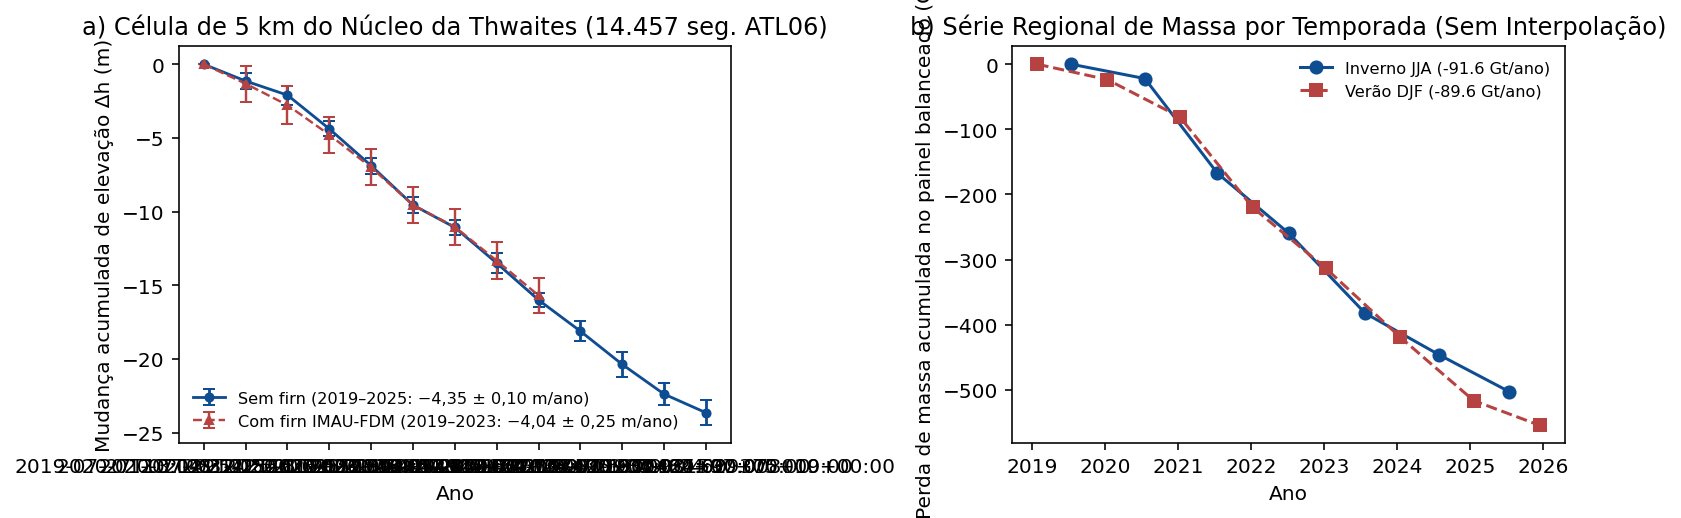

,season,t_center,N_obs,N_blocks,dh_ice_m,sigma_dh_ice_m,dM_Gt,sigma_dM_Gt
window,,,,,,,,
JJA 2019,JJA,2019-07-27T13:04:32.155626+00:00,1405,3,0.000,0.000,0.000,0.000
DJF 2019/2020,DJF,2020-01-07T08:54:50.808091+00:00,1690,3,-1.139,0.561,-0.026,0.013
JJA 2020,JJA,2020-07-29T02:50:19.559816+00:00,531,1,-2.096,0.654,-0.048,0.015
DJF 2020/2021,DJF,2021-01-22T11:03:26.894441+00:00,910,3,-4.386,0.504,-0.101,0.012
JJA 2021,JJA,2021-08-20T21:21:48.054912+00:00,224,1,-6.886,0.549,-0.158,0.013
DJF 2021/2022,DJF,2022-01-23T13:14:52.830464+00:00,870,3,-9.557,0.523,-0.219,0.012
JJA 2022,JJA,2022-07-21T09:02:48.667033+00:00,1113,3,-11.077,0.506,-0.254,0.012
DJF 2022/2023,DJF,2023-01-01T04:53:04.563490+00:00,1756,3,-13.495,0.679,-0.309,0.016
JJA 2023,JJA,2023-07-22T11:13:14.110934+00:00,929,3,-15.999,0.497,-0.367,0.011


In [2]:
ser_jja = json.loads((DATA_DIR / "jja_serie_massa_temporada.json").read_text(encoding="utf-8"))
ser_djf = json.loads((DATA_DIR / "djf_serie_massa_temporada.json").read_text(encoding="utf-8"))
nuc_ser = pd.read_csv(DATA_DIR / "celula_nucleo_thwaites_serie.csv")
nuc_firn = pd.read_csv(DATA_DIR / "celula_nucleo_thwaites_com_firn_serie.csv")

df_sj = pd.DataFrame(ser_jja["serie"])
df_sd = pd.DataFrame(ser_djf["serie"])

fig, ax = plt.subplots(1, 2, figsize=(11.0, 3.7))
ax[0].errorbar(nuc_ser["t_center"], nuc_ser["dh_ice_m"], yerr=nuc_ser["sigma_dh_ice_m"],
               fmt="o-", color="#0F4D92", lw=1.4, ms=4, capsize=3, label="Sem firn (2019–2025: −4,35 ± 0,10 m/ano)")
ax[0].errorbar(nuc_firn["t_center"], nuc_firn["dh_ice_m"], yerr=nuc_firn["sigma_dh_ice_m"],
               fmt="^--", color="#B64342", lw=1.2, ms=4, capsize=3, label="Com firn IMAU-FDM (2019–2023: −4,04 ± 0,25 m/ano)")
ax[0].set_xlabel("Ano")
ax[0].set_ylabel("Mudança acumulada de elevação Δh (m)")
ax[0].set_title("a) Célula de 5 km do Núcleo da Thwaites (14.457 seg. ATL06)")
ax[0].legend(frameon=False, fontsize=8)

ax[1].plot(df_sj["epoca_media"], df_sj["massa_acumulada_Gt"], "o-", color="#0F4D92", lw=1.5, label=f"Inverno JJA ({ser_jja['taxa_Gt_por_ano_ajuste_linear']:.1f} Gt/ano)")
ax[1].plot(df_sd["epoca_media"], df_sd["massa_acumulada_Gt"], "s--", color="#B64342", lw=1.5, label=f"Verão DJF ({ser_djf['taxa_Gt_por_ano_ajuste_linear']:.1f} Gt/ano)")
ax[1].set_xlabel("Ano")
ax[1].set_ylabel("Perda de massa acumulada no painel balanceado (Gt)")
ax[1].set_title("b) Série Regional de Massa por Temporada (Sem Interpolação)")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

nuc_ser[["window", "season", "t_center", "N_obs", "N_blocks", "dh_ice_m", "sigma_dh_ice_m", "dM_Gt", "sigma_dM_Gt"]].set_index("window").round(3)